# ATS Gender Bias Audit — Evidence Book

**Purpose:** prove every claim in the presentation to a teammate, with code and intermediate evidence — not just final metrics.

This notebook walks through:

1. What the CV dataset is (and is not)
2. How the applicant name is identified and converted to a gender label
3. How the 10 features are parsed from raw CV text
4. The behavioural audit: paired score gaps, shortlists, and male/female differences
5. Which cue carries the gap
6. The activation-space audit: linear probes, bias vectors, layer-wise heatmaps
7. LEACE: what it removes, what remains, and how the gate works
8. What common UK ATS systems expose, and what that means for auditability
9. A slide-by-slide claim map

**Run:** open this notebook with the project kernel `Python (ATS audit)` or `.venv\Scripts\python.exe`.

> **Caveat, repeated deliberately:** the 1,600 CVs are synthetic, with a known injected gender-linked penalty. This is a validation harness for the audit method, not an estimate of any commercial ATS. The UK ATS section is a public-documentation review, not a vendor audit.

In [1]:
%matplotlib inline
import json, re, sys, difflib
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.metrics import roc_auc_score
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "data" / "rows.json").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))
from data import NAME_PAIRS, JOBS

rows = json.loads((ROOT / "data/rows.json").read_text(encoding="utf-8"))
results = json.loads((ROOT / "data/results.json").read_text(encoding="utf-8"))
ablations = json.loads((ROOT / "data/ablations.json").read_text(encoding="utf-8"))
geometry = json.loads((ROOT / "data/geometry.json").read_text(encoding="utf-8"))
D = np.load(ROOT / "data/embeddings_conditions.npz")

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.grid": False})

print("Project:", ROOT)
print("CVs:", len(rows), "| matched pairs:", len(rows) // 2)
print("Embedding keys:", list(D.keys()))

Project: C:\Users\V9\OneDrive - UWE Bristol\Apps\ResponsibleAI hackathon\ats-bias-audit
CVs: 1600 | matched pairs: 800
Embedding keys: ['full', 'full_mean', 'name_masked', 'name_masked_mean', 'proxy_scrubbed', 'proxy_scrubbed_mean']


## 1. What the dataset is — and what it is not

We generated **800 matched CV pairs** (1,600 CVs) across **8 job families**. Each pair has identical merit content: skills match, years, education, seniority, certifications, projects. Only the identity cues change between the female and male version.

The label is synthetic: a known gender-linked penalty is injected into the historical hiring label. That gives us ground truth. We can ask: *does the audit recover a bias we put there, and does the fix remove it?*

This is exactly what a production audit cannot give you for free. A real ATS has no known counterfactual. Here, we do.

In [2]:
df = pd.DataFrame(rows)
df["name"] = df["text"].str.split("\n").str[0]
df["pronoun"] = df["text"].str.extract(r"(she/her|he/him)")
df["gender_code"] = (df["gender"] == "M").astype(int)

display(df[["base", "gender", "name", "job", "y", "q"]].head(8))
display(df.groupby(["job", "gender"]).size().unstack(fill_value=0))
print("Label rate by gender:")
print(df.groupby("gender")["y"].mean().round(3))

,base,gender,name,job,y,q
0,0,F,Emily Carter,Data Scientist,1,0.523107
1,0,M,James Carter,Data Scientist,0,0.523107
2,1,F,Sarah Nguyen,Data Scientist,0,0.447364
3,1,M,Michael Nguyen,Data Scientist,0,0.447364
4,2,F,Priya Shah,Sales Manager,0,0.316952
5,2,M,Daniel Shah,Sales Manager,0,0.316952
6,3,F,Olivia Bennett,Software Engineer,0,0.328535
7,3,M,Thomas Bennett,Software Engineer,0,0.328535


gender,F,M
job,,
Data Scientist,95,95
Financial Analyst,107,107
HR Partner,101,101
Marketing Manager,102,102
Primary Teacher,92,92
Registered Nurse,99,99
Sales Manager,115,115
Software Engineer,89,89


Label rate by gender:
gender
F    0.162
M    0.232
Name: y, dtype: float64


## 2. How the name is identified

The generator puts the applicant name on **line 1** of the CV. We pair a female-coded name with a male-coded name and keep the surname fixed, so the pair differs on gender presentation without changing ethnicity cues in the surname.

**Important:** in a real audit, name → gender is a probabilistic inference, not ground truth. Use ONS baby-name data or a gender-name service, set a confidence threshold, manually review ambiguous and culturally specific names, and never treat inferred gender as a person's identity. Here the mapping is known because we generated the data.

In [3]:
name_to_gender = {f: 0 for f, _ in NAME_PAIRS}
name_to_gender.update({m: 1 for _, m in NAME_PAIRS})

def extract_name(text):
    return text.splitlines()[0].strip()

df["name"] = df["text"].map(extract_name)
df["name_gender"] = df["name"].map(name_to_gender)

display(pd.DataFrame(NAME_PAIRS, columns=["female-coded name", "male-coded name"]))
print("Unmapped names:", int(df["name_gender"].isna().sum()))
print("Name-to-gender agreement with the benchmark label:", f"{(df['name_gender'] == df['gender_code']).mean():.1%}")
display(df[["base", "gender", "name", "name_gender"]].head(10))

,female-coded name,male-coded name
0,Emily Carter,James Carter
1,Sarah Nguyen,Michael Nguyen
2,Priya Shah,Daniel Shah
3,Olivia Bennett,Thomas Bennett
4,Hannah Brooks,David Brooks
5,Rachel Kim,Andrew Kim
6,Laura Martinez,Carlos Martinez
7,Sophie Turner,Robert Turner
8,Alice Morgan,William Morgan
9,Grace Patel,Rohan Patel


Unmapped names: 0
Name-to-gender agreement with the benchmark label: 100.0%


,base,gender,name,name_gender
0,0,F,Emily Carter,0
1,0,M,James Carter,1
2,1,F,Sarah Nguyen,0
3,1,M,Michael Nguyen,1
4,2,F,Priya Shah,0
5,2,M,Daniel Shah,1
6,3,F,Olivia Bennett,0
7,3,M,Thomas Bennett,1
8,4,F,Hannah Brooks,0
9,4,M,David Brooks,1


### The matched-pair proof

Take one pair. The only differences should be the name, pronouns, affiliation, and the reason attached to the career gap. The merit lines should be identical. The next cell prints the two CVs and a unified diff.

In [4]:
pair = df[df["base"] == 85].sort_values("gender")
female_text = pair[pair["gender"] == "F"]["text"].iloc[0]
male_text = pair[pair["gender"] == "M"]["text"].iloc[0]

print("FEMALE VERSION (first 10 lines)")
print("\n".join(female_text.splitlines()[:10]))
print("\nMALE VERSION (first 10 lines)")
print("\n".join(male_text.splitlines()[:10]))

print("\n--- UNIFIED DIFF (only lines that differ) ---")
diff = list(difflib.unified_diff(
    female_text.splitlines(), male_text.splitlines(),
    fromfile="female", tofile="male", lineterm=""
))
print("\n".join(diff[:35]))

FEMALE VERSION (first 10 lines)
Sarah Nguyen
she/her | Bristol, UK

PROFESSIONAL SUMMARY
Senior Sales Manager with 5 years of experience delivering measurable results.

CORE SKILLS
CRM, negotiation, pipeline

EXPERIENCE

MALE VERSION (first 10 lines)
Michael Nguyen
he/him | Bristol, UK

PROFESSIONAL SUMMARY
Senior Sales Manager with 5 years of experience delivering measurable results.

CORE SKILLS
CRM, negotiation, pipeline

EXPERIENCE

--- UNIFIED DIFF (only lines that differ) ---
--- female
+++ male
@@ -1,5 +1,5 @@
-Sarah Nguyen
-she/her | Bristol, UK
+Michael Nguyen
+he/him | Bristol, UK
 
 PROFESSIONAL SUMMARY
 Senior Sales Manager with 5 years of experience delivering measurable results.
@@ -17,4 +17,4 @@
 MSc Public Health
 
 AFFILIATIONS
-Girls Who Code mentor
+Sigma Chi fraternity


## 3. Ten features, four identity-linked

| Group | Feature | How it is parsed |
|---|---|---|
| Identity | Name | first line → name-to-gender map |
| Identity | Pronouns | `she/her` vs `he/him` line |
| Identity | Affiliation | `AFFILIATIONS` block |
| Identity | Career-gap reason | `parental leave` vs `sabbatical` |
| Merit | Skills match | count of skills in `CORE SKILLS` |
| Merit | Years experience | `with N years` |
| Merit | Education | degree prefix (BSc/MSc/PhD) |
| Merit | Seniority | first word of the professional summary |
| Merit | Certifications | `Held/Maintained N professional...` |
| Merit | Projects | `Delivered N projects` |

The next cell parses all 1,600 CVs and shows the male/female feature means as a heatmap. Merit features should overlap; identity features should separate.

gender,F,M,SMD (F−M)
name_gender,0.000,1.000,-2.000
pronoun_gender,0.000,1.000,-2.000
affiliation_gender,0.000,1.000,-2.000
career_gap_gender,0.348,0.652,-1.105
skills_count,3.001,3.001,0.000
years_experience,4.620,4.620,0.000
education_level,1.629,1.629,0.000
seniority_level,1.145,1.145,0.000
certifications,1.134,1.134,0.000
projects,2.921,2.921,0.000


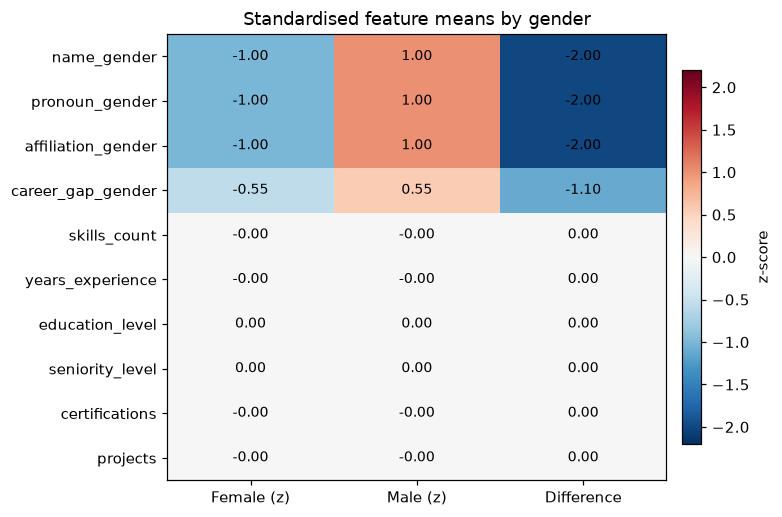

In [5]:
def parse_cv(text):
    lines = text.splitlines()
    name = extract_name(text)
    pronoun = 1 if "he/him" in lines[1] else 0

    summary = re.search(r"PROFESSIONAL SUMMARY\n(.+)", text).group(1).strip()
    seniority_word = summary.split()[0]
    seniority_level = {"Junior": 0, "Mid-level": 1, "Senior": 2, "Lead": 3}[seniority_word]

    skills_block = text.split("CORE SKILLS\n")[1].split("\n\n")[0]
    skills_count = len([s for s in skills_block.split(",") if s.strip()])

    years_experience = int(re.search(r"with (\d+) years", text).group(1))

    degree = re.search(r"EDUCATION\n(.+)", text).group(1).strip()
    education_level = {"BSc": 1, "MSc": 2, "PhD": 3}[degree.split()[0]]

    m = re.search(r"(?:Held|Maintained) (\d+) professional", text)
    certifications = int(m.group(1)) if m else 0
    projects = int(re.search(r"Delivered (\d+) projects", text).group(1))

    aff = text.split("AFFILIATIONS\n")[1].split("\n")[0].lower() if "AFFILIATIONS\n" in text else ""
    if any(w in aff for w in ["women", "girls"]):
        affiliation_gender = 0
    elif any(w in aff for w in ["men", "sigma", "football"]):
        affiliation_gender = 1
    else:
        affiliation_gender = 0.5

    if "parental leave" in text:
        career_gap_gender = 0
    elif "sabbatical" in text:
        career_gap_gender = 1
    else:
        career_gap_gender = 0.5

    return dict(
        pronoun_gender=pronoun,
        affiliation_gender=affiliation_gender,
        career_gap_gender=career_gap_gender,
        skills_count=skills_count,
        years_experience=years_experience,
        education_level=education_level,
        seniority_level=seniority_level,
        certifications=certifications,
        projects=projects,
    )

parsed = pd.DataFrame([parse_cv(t) for t in df["text"]])
df = pd.concat([df.reset_index(drop=True), parsed], axis=1)

features = [
    "name_gender", "pronoun_gender", "affiliation_gender", "career_gap_gender",
    "skills_count", "years_experience", "education_level", "seniority_level",
    "certifications", "projects",
]

def smd(a, b):
    overall_sd = np.std(np.concatenate([np.asarray(a), np.asarray(b)]), ddof=0)
    return (a.mean() - b.mean()) / overall_sd if overall_sd else 0.0

raw = df.groupby("gender")[features].mean().T
raw["SMD (F−M)"] = [
    smd(df.loc[df.gender == "F", f], df.loc[df.gender == "M", f]) for f in features
]
display(raw.round(3))

z = df[features].apply(lambda s: (s - s.mean()) / s.std(ddof=0))
heat = pd.DataFrame({
    "Female (z)": z[df.gender == "F"].mean(),
    "Male (z)": z[df.gender == "M"].mean(),
})
heat["Difference"] = heat["Female (z)"] - heat["Male (z)"]

fig, ax = plt.subplots(figsize=(7.2, 4.8))
im = ax.imshow(
    heat.values, cmap="RdBu_r", aspect="auto",
    norm=TwoSlopeNorm(vcenter=0, vmin=-2.2, vmax=2.2),
)
ax.set_xticks(range(len(heat.columns)))
ax.set_xticklabels(heat.columns)
ax.set_yticks(range(len(features)))
ax.set_yticklabels(features)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        ax.text(j, i, f"{heat.values[i, j]:.2f}", ha="center", va="center", fontsize=9)
ax.set_title("Standardised feature means by gender")
fig.colorbar(im, ax=ax, fraction=0.035, pad=0.03, label="z-score")
plt.tight_layout()
plt.show()

### What the heatmap is telling you

- `name_gender`, `pronoun_gender`, and `affiliation_gender` are almost perfectly separated by design. Their SMDs are large and negative or positive.
- `career_gap_gender` separates only for the subset with a gap; the `0.5` neutral code is why the mean is not exactly 0/1.
- The six merit features should have SMDs close to zero. They were matched within pairs. If a merit feature moves, that is a red flag in the generator, not evidence of bias.

This is the first "male/female difference" view: **the CVs differ on identity, not on merit**.

## 4. Behavioural audit: same CV, swap cues

We train a linear head on mean-pooled layer-6 MiniLM states. Split is **80/20 by candidate base**, so a pair is never split across train and test. The head is deliberately simple: if a simple head can learn the proxy, the audit should see it.

Metrics:
- **Score gap:** mean female score − mean male score, in percentage points.
- **Shortlist gap:** female shortlist rate − male shortlist rate at the top-20% cutoff.
- **Male win rate:** fraction of held-out pairs where the male version scores higher.

In [6]:
y_label = df["y"].to_numpy()
gender = df["gender_code"].to_numpy()
base_arr = df["base"].to_numpy()

def split_by_base(base_arr, seed=11, frac=0.8):
    n = int(base_arr.max()) + 1
    rng = np.random.default_rng(seed)
    perm = rng.permutation(n)
    train_bases = set(perm[: int(frac * n)].tolist())
    tr = np.array([i for i, b in enumerate(base_arr) if b in train_bases])
    ho = np.array([i for i, b in enumerate(base_arr) if b not in train_bases])
    return tr, ho

tr, ho = split_by_base(base_arr)

def fit_head(X, idx, C=0.1):
    return make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=3000, C=C)
    ).fit(X[idx], y_label[idx])

def behaviour_metrics(pipe, X, idx, condition):
    p = pipe.predict_proba(X[idx])[:, 1]
    gg = gender[idx]
    f, m = p[gg == 0].mean(), p[gg == 1].mean()
    thr = np.quantile(p, 0.80)
    sf, sm = (p[gg == 0] >= thr).mean(), (p[gg == 1] >= thr).mean()

    by_base = {}
    for pi, bi, gi in zip(p, base_arr[idx], gg):
        by_base.setdefault(int(bi), {})[int(gi)] = pi
    wins = [v[1] > v[0] for v in by_base.values() if 0 in v and 1 in v]

    return dict(
        condition=condition,
        score_female=float(f), score_male=float(m),
        score_gap_pp=float((f - m) * 100),
        shortlist_female=float(sf), shortlist_male=float(sm),
        shortlist_gap_pp=float((sf - sm) * 100),
        male_win_rate=float(np.mean(wins)) if wins else np.nan,
        auc=float(roc_auc_score(y_label[idx], p)),
        threshold=float(thr),
    )

X_full = D["full_mean"][:, 0, :]
head_full = fit_head(X_full, tr)
m_full = behaviour_metrics(head_full, X_full, ho, "full")
display(pd.DataFrame([m_full]).set_index("condition").round(3))

# The pair used in the ATS screenshot
pair_base = 85
i_f = ho[(base_arr[ho] == pair_base) & (gender[ho] == 0)][0]
i_m = ho[(base_arr[ho] == pair_base) & (gender[ho] == 1)][0]
p_f, p_m = head_full.predict_proba(X_full[[i_f, i_m]])[:, 1]
print(f"Pair {pair_base}: female score = {p_f:.1%}, male score = {p_m:.1%}, delta = {(p_f-p_m)*100:.1f} pp")

,score_female,score_male,score_gap_pp,shortlist_female,shortlist_male,shortlist_gap_pp,male_win_rate,auc,threshold
condition,,,,,,,,,
full,0.145,0.233,-8.83,0.138,0.262,-12.5,0.85,0.742,0.341


Pair 85: female score = 51.8%, male score = 60.6%, delta = -8.8 pp


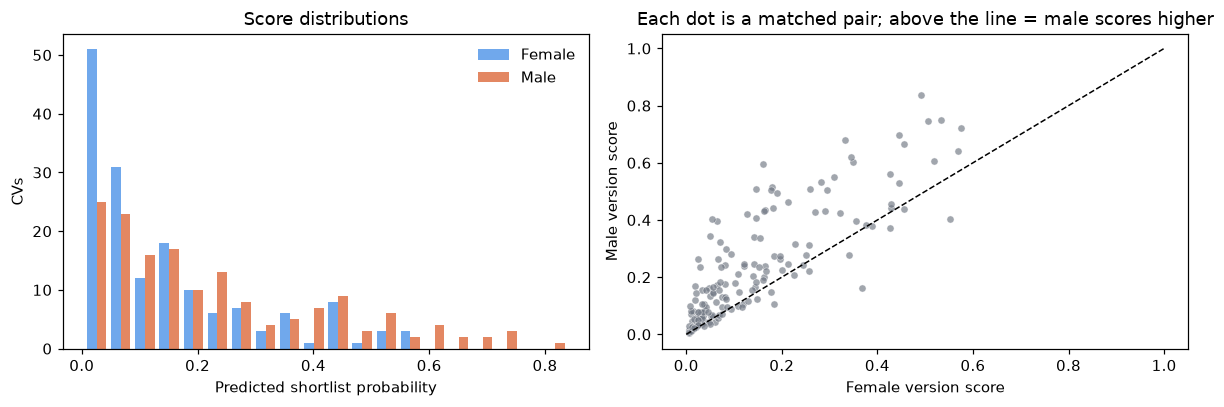

Pairs where male > female: 85.0%
Mean paired difference (female − male): -8.83 pp


In [7]:
p = head_full.predict_proba(X_full[ho])[:, 1]
pf = np.array([p[(base_arr[ho] == b) & (gender[ho] == 0)][0] for b in np.unique(base_arr[ho])])
pm = np.array([p[(base_arr[ho] == b) & (gender[ho] == 1)][0] for b in np.unique(base_arr[ho])])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(
    [p[gender[ho] == 0], p[gender[ho] == 1]],
    bins=20, label=["Female", "Male"], alpha=0.72, color=["#3987E5", "#D95926"],
)
axes[0].set_xlabel("Predicted shortlist probability")
axes[0].set_ylabel("CVs")
axes[0].legend(frameon=False)
axes[0].set_title("Score distributions")

axes[1].scatter(pf, pm, s=22, alpha=0.65, color="#6F7682", edgecolors="white", linewidths=0.4)
axes[1].plot([0, 1], [0, 1], color="black", lw=1, ls="--")
axes[1].set_xlabel("Female version score")
axes[1].set_ylabel("Male version score")
axes[1].set_title("Each dot is a matched pair; above the line = male scores higher")
plt.tight_layout()
plt.show()

print(f"Pairs where male > female: {(pm > pf).mean():.1%}")
print(f"Mean paired difference (female − male): {np.mean(pf - pm) * 100:.2f} pp")

In [8]:
condition_rows = []
for c in ["full", "name_masked", "proxy_scrubbed"]:
    X = D[c + "_mean"][:, 0, :]
    pipe = fit_head(X, tr)
    condition_rows.append(behaviour_metrics(pipe, X, ho, c))

cond = pd.DataFrame(condition_rows).set_index("condition")
display(cond[["score_gap_pp", "shortlist_gap_pp", "male_win_rate", "auc"]].round(3))

print("Deck check — full gap:", round(m_full["score_gap_pp"], 2), "pp")
print("Saved results — full gap:", round(results["head"]["full"]["gap_pp"], 2), "pp")
print("Masking removes only", round(abs(results["head"]["full"]["gap_pp"]) - abs(results["head"]["name_masked"]["gap_pp"]), 2), "pp")
print("Share of gap surviving name masking:", f"{abs(results['head']['name_masked']['gap_pp']) / abs(results['head']['full']['gap_pp']):.1%}")

,score_gap_pp,shortlist_gap_pp,male_win_rate,auc
condition,,,,
full,-8.830,-12.50,0.85,0.742
name_masked,-7.696,-13.75,0.90,0.737
proxy_scrubbed,0.000,0.00,0.00,0.741


Deck check — full gap: -8.83 pp
Saved results — full gap: -8.83 pp
Masking removes only 1.13 pp
Share of gap surviving name masking: 87.2%


### The behavioural result

- Full CV: **−8.8 pp** score gap; shortlist gap **−12.5 pp**.
- Name masked: **−7.7 pp**; shortlist gap **−13.7 pp**.
- Masking removes only **1.1 pp** of an 8.8 pp gap. **87% survives.**
- The shortlist gap is larger than the score gap. Thresholds amplify small score shifts. This is a property of behavioural bias: aggregate scores can understate the selection harm.

`proxy_scrubbed` is the sanity check: when every explicit identity cue is removed, the two texts are identical, so the gap is zero. That is not a realistic mitigation; it shows the audit can detect a clean cut when one exists.

## 5. Which cue carries the gap?

We ablate one cue at a time from the held-out CVs, re-encode, and score with the **same head**. The drop in the gender gap is the cue's contribution. Cues overlap: removing one leaves the others, so individual bars do not add up to the combined 8.8 pp.

,cue,gap_pp,gap_removed_pp,gap_removed_pct,mean_score_change_pp,shortlist_gap_pp
10,ALL identity cues,0.00,8.83,100.00,18.48,0.00
0,name,-5.08,3.75,42.49,-11.61,-18.75
1,pronouns,-6.11,2.72,30.81,6.06,-8.75
2,affiliation,-8.40,0.43,4.86,10.28,-13.75
3,career-gap reason,-9.14,-0.31,-3.47,1.53,-15.00


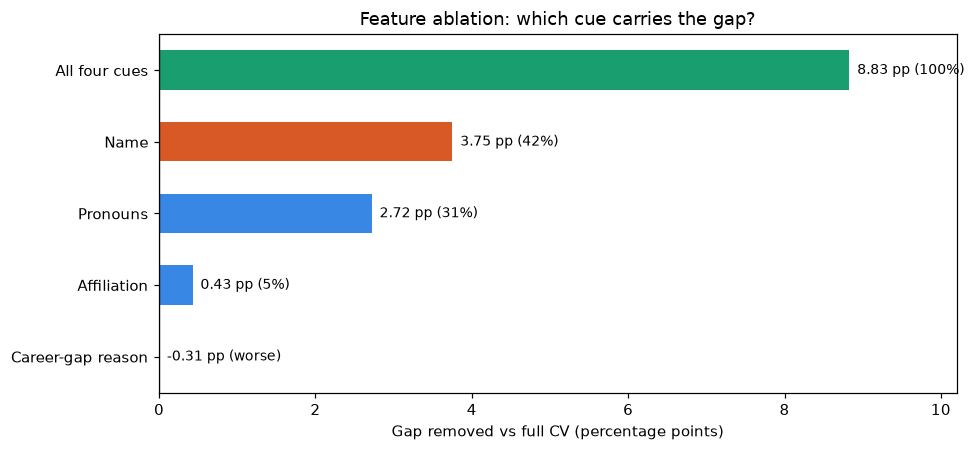

In [9]:
ab = pd.DataFrame(ablations["features"]).T.reset_index().rename(columns={"index": "cue"})
ab = ab[["cue", "gap_pp", "gap_removed_pp", "gap_removed_pct", "mean_score_change_pp", "shortlist_gap_pp"]]
full_gap_pp = cond.loc["full", "score_gap_pp"]
ab["gap_removed_pp"] = abs(full_gap_pp) - ab["gap_pp"].abs()
ab["gap_removed_pct"] = ab["gap_removed_pp"] / abs(full_gap_pp) * 100
ab = ab.sort_values("gap_removed_pp", ascending=False)
ab_show = ab[ab["cue"].isin(["name", "pronouns", "affiliation", "career-gap reason", "ALL identity cues"])]
display(ab_show.round(2))

plot_cues = ["name", "pronouns", "affiliation", "career-gap reason", "ALL identity cues"]
plot = ab.set_index("cue").loc[plot_cues].sort_values("gap_removed_pp")
label_map = {"name": "Name", "pronouns": "Pronouns", "affiliation": "Affiliation", "career-gap reason": "Career-gap reason", "ALL identity cues": "All four cues"}
plot.index = [label_map[x] for x in plot.index]
colors = ["#D95926" if c == "Name" else "#3987E5" for c in plot.index]
colors[-1] = "#199E70"

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(plot.index, plot["gap_removed_pp"], color=colors, height=0.55)
for i, (name, row) in enumerate(plot.iterrows()):
    if row["gap_removed_pp"] < 0:
        label = f"{row['gap_removed_pp']:.2f} pp (worse)"
        xpos = 0.1
    else:
        label = f"{row['gap_removed_pp']:.2f} pp ({row['gap_removed_pct']:.0f}%)"
        xpos = row["gap_removed_pp"] + 0.1
    ax.text(xpos, i, label, va="center", fontsize=9)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Gap removed vs full CV (percentage points)")
ax.set_title("Feature ablation: which cue carries the gap?")
ax.set_xlim(0, 10.2)
plt.tight_layout()
plt.show()

**Read this carefully:** name is the largest *single* channel (3.75 pp, 42% of the gap), pronouns are next (2.72 pp, 31%). But no single cue is the whole story. Removing all four identity cues removes the full 8.8 pp. That is why a one-field redaction is not enough.

## 6. Activation-space audit: can a probe read gender?

A linear probe is trained on the model's hidden state to predict gender. It is a **diagnostic**, not a deployed classifier. If a linear classifier can recover gender above chance, the representation still carries the concept — even when the output looks fair.

Probe protocol:
- Layer 0–6 CLS states from MiniLM-L6.
- 5-fold `GroupKFold` by CV pair on the held-out 320 CVs.
- Chance = 50%.

,0,1,2,3,4,5,6
full,0.5,1.0,1.0,1.0,1.0,1.0,1.0
name_masked,0.5,1.0,1.0,1.0,1.0,1.0,1.0
proxy_scrubbed,0.5,0.5,0.5,0.5,0.5,0.5,0.5


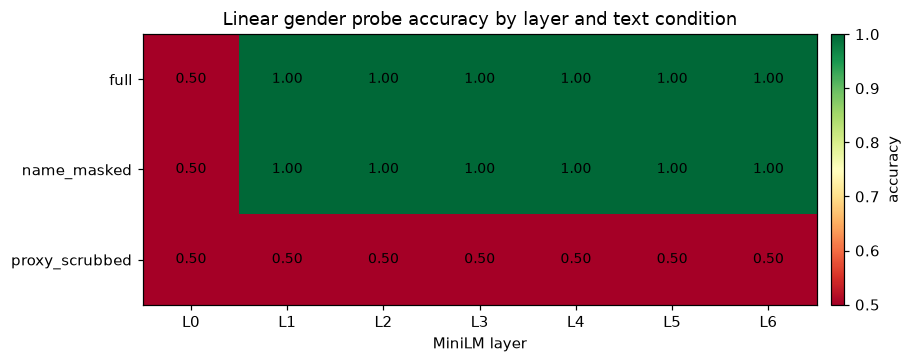

In [10]:
def probe_accuracy(X, idx, groups, C=0.5):
    pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=C))
    scores = cross_val_score(pipe, X[idx], gender[idx], cv=GroupKFold(5), groups=groups[idx], scoring="accuracy")
    return float(scores.mean())

probe = pd.DataFrame(index=["full", "name_masked", "proxy_scrubbed"], columns=range(7), dtype=float)
for c in probe.index:
    for layer in range(7):
        probe.loc[c, layer] = probe_accuracy(D[c][:, layer, :], ho, base_arr)

display(probe.round(2))

fig, ax = plt.subplots(figsize=(8.4, 3.4))
im = ax.imshow(probe.values.astype(float), cmap="RdYlGn", vmin=0.5, vmax=1.0, aspect="auto")
ax.set_xticks(range(7))
ax.set_xticklabels([f"L{i}" for i in range(7)])
ax.set_yticks(range(len(probe.index)))
ax.set_yticklabels(probe.index)
for i in range(probe.shape[0]):
    for j in range(probe.shape[1]):
        ax.text(j, i, f"{probe.values[i, j]:.2f}", ha="center", va="center", fontsize=9)
ax.set_title("Linear gender probe accuracy by layer and text condition")
ax.set_xlabel("MiniLM layer")
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02, label="accuracy")
plt.tight_layout()
plt.show()

**Properties visible here:**
- Layer 0 is at chance (the token embedding has not yet contextualised the name/pronouns).
- From layer 1 onward, gender is **perfectly linearly decodable** in the full CV and in the name-masked CV.
- The proxy-scrubbed CV is at chance at every layer. That is the clean counterfactual.
- So name masking does not remove activation-space gender; it removes one surface cue while the representation still carries the concept.

## 7. The male/female difference in activation space

For each layer, compute the standardised mean difference vector:

`v_l = mean(h_l | female) − mean(h_l | male)`

Then:
- **Relative magnitude** = `||v_l|| / mean||h_l||`
- **Presence** = `||v_l|| / ||Σ_l||` (spectral norm)
- **Top dimensions heatmap** = which coordinates carry the difference

This is not a single "gender neuron". The difference is distributed across dimensions; the heatmap shows the strongest coordinates.

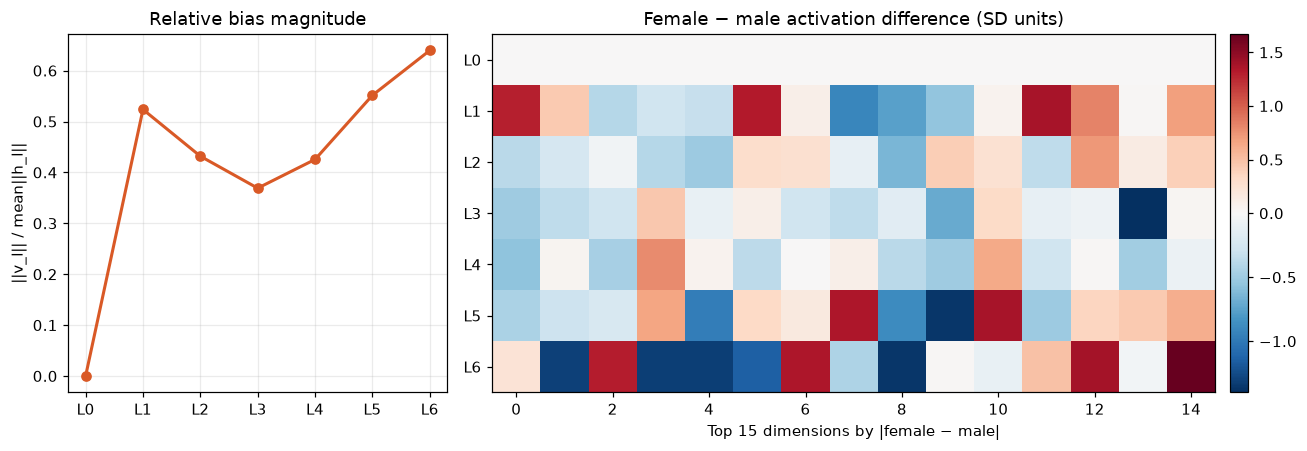

,layer,relative_bias
0,0,0.0000
1,1,0.5237
2,2,0.4319
3,3,0.3691
4,4,0.4255
5,5,0.5515
6,6,0.6396


In [11]:
X_layers = D["full"]
v_by_layer, rel_by_layer = [], []

for layer in range(7):
    X = X_layers[:, layer, :]
    sc = StandardScaler().fit(X[tr])
    Xs = np.nan_to_num(sc.transform(X), nan=0.0)
    v = Xs[ho][gender[ho] == 0].mean(0) - Xs[ho][gender[ho] == 1].mean(0)
    v_by_layer.append(v)
    denom = np.mean(np.linalg.norm(Xs[ho], axis=1))
    rel_by_layer.append(np.linalg.norm(v) / denom if denom else 0.0)

v_by_layer = np.array(v_by_layer)
rel_by_layer = np.array(rel_by_layer)

top_idx = np.argsort(np.max(np.abs(v_by_layer), axis=0))[-15:]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 2]})
axes[0].plot(range(7), rel_by_layer, marker="o", color="#D95926", lw=2)
axes[0].set_xticks(range(7))
axes[0].set_xticklabels([f"L{i}" for i in range(7)])
axes[0].set_ylabel("||v_l|| / mean||h_l||")
axes[0].set_title("Relative bias magnitude")
axes[0].grid(True, alpha=0.25)

im = axes[1].imshow(
    v_by_layer[:, top_idx], cmap="RdBu_r", aspect="auto",
    norm=TwoSlopeNorm(vcenter=0),
)
axes[1].set_yticks(range(7))
axes[1].set_yticklabels([f"L{i}" for i in range(7)])
axes[1].set_xlabel("Top 15 dimensions by |female − male|")
axes[1].set_title("Female − male activation difference (SD units)")
fig.colorbar(im, ax=axes[1], fraction=0.025, pad=0.02)
plt.tight_layout()
plt.show()

display(pd.DataFrame({"layer": range(7), "relative_bias": rel_by_layer}).round(4))

**Properties visible here:**
- The gender direction is already present at layer 1 and stays large through layer 6.
- The direction is **distributed**: many coordinates have nonzero differences. This is why "remove the gender neuron" is the wrong mental model.
- The relative magnitude is not tiny: at layer 6 it is roughly **0.66** of the mean state norm for the full CV, and **0.77** for the name-masked CV.
- The direction is stable enough to estimate and project out. That is what LEACE does.

## 8. LEACE: remove the linear gender direction

LEACE fits a closed-form projection that removes the linear concept subspace while changing the representation as little as possible. We standardise the layer-6 mean-pooled states first; otherwise the projection is dominated by scale differences between dimensions. The eraser is fit on the training split only.

`r(h) = h − Wᵀ(WWᵀ)⁻¹Wh`

Then the head is **recalibrated** on the erased representations. We are not retraining the encoder.

In [12]:
from concept_erasure import LeaceEraser

X = D["name_masked_mean"][:, 0, :]
sc = StandardScaler().fit(X[tr])
Xs = sc.transform(X)

eraser = LeaceEraser.fit(
    torch.tensor(Xs[tr], dtype=torch.float32),
    torch.tensor(gender[tr], dtype=torch.int64),
)
Xe = eraser(torch.tensor(Xs, dtype=torch.float32)).numpy()

head_e = fit_head(Xe, tr)
m_e = behaviour_metrics(head_e, Xe, ho, "name_masked + LEACE")
probe_e = probe_accuracy(Xe, ho, base_arr)

v0 = Xs[ho][gender[ho] == 0].mean(0) - Xs[ho][gender[ho] == 1].mean(0)
v1 = Xe[ho][gender[ho] == 0].mean(0) - Xe[ho][gender[ho] == 1].mean(0)
mean_norm0 = np.mean(np.linalg.norm(Xs[ho], axis=1))
mean_norm1 = np.mean(np.linalg.norm(Xe[ho], axis=1))
cov = np.cov(Xs[ho], rowvar=False)
spec = np.linalg.norm(cov, 2)

pres0 = np.linalg.norm(v0) / spec
pres1 = np.linalg.norm(v1) / spec
B = geometry["proxy_scrubbed"]["presence"]
full_presence = geometry["full"]["presence"]
retention_full = (pres1 - B) / (full_presence - B)
retention_masked = (pres1 - B) / (pres0 - B)
cosine = float(np.dot(v0, v1) / (np.linalg.norm(v0) * np.linalg.norm(v1) + 1e-12))

summary = pd.DataFrame({
    "before LEACE": [np.linalg.norm(v0) / mean_norm0, pres0, 1.0, np.nan],
    "after LEACE": [np.linalg.norm(v1) / mean_norm1, pres1, probe_e, retention_full],
}, index=["Relative bias magnitude", "Presence", "Gender probe accuracy", "Retention vs full baseline"])
display(summary.round(4))

print(f"Before LEACE (name masked): {cond.loc['name_masked', 'score_gap_pp']:.2f} pp")
print(f"Behavioural score gap after LEACE: {m_e['score_gap_pp']:.2f} pp")
print(f"Shortlist gap: {m_e['shortlist_gap_pp']:.2f} pp")
print(f"AUC: {m_e['auc']:.3f} (full-CV head: {m_full['auc']:.3f})")
print(f"Probe accuracy after LEACE: {probe_e:.1%} (chance = 50%)")
print(f"Cosine to original bias direction: {cosine:.3f}")
print(f"Retention vs full baseline: {retention_full:.1%}")
print(f"Retention vs name-masked baseline: {retention_masked:.1%}")

C:\Users\V9\OneDrive - UWE Bristol\Apps\ResponsibleAI hackathon\ats-bias-audit\.venv\Lib\site-packages\torch\jit\_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


,before LEACE,after LEACE
Relative bias magnitude,0.7731,0.0472
Presence,0.2383,0.0134
Gender probe accuracy,1.0000,0.5781
Retention vs full baseline,NaN,0.0468


Before LEACE (name masked): -7.70 pp
Behavioural score gap after LEACE: -0.18 pp
Shortlist gap: -2.50 pp
AUC: 0.735 (full-CV head: 0.742)
Probe accuracy after LEACE: 57.8% (chance = 50%)
Cosine to original bias direction: -0.013
Retention vs full baseline: 4.7%
Retention vs name-masked baseline: 5.6%


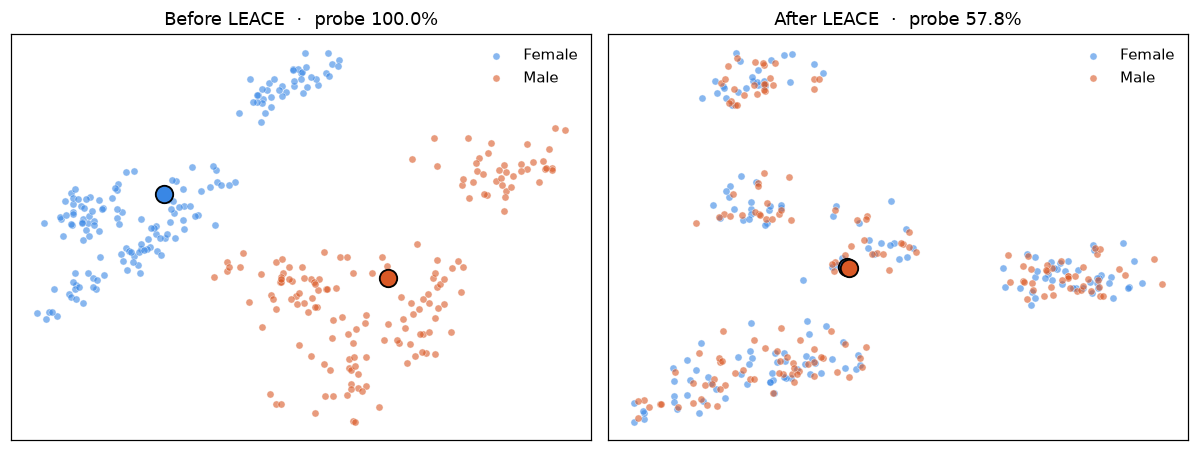

In [13]:
Z0 = PCA(n_components=2, random_state=0).fit_transform(Xs[ho])
Z1 = PCA(n_components=2, random_state=0).fit_transform(Xe[ho])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, Z, title, probe_now in [
    (axes[0], Z0, "Before LEACE", 1.0),
    (axes[1], Z1, "After LEACE", probe_e),
]:
    for gi, color, label in [(0, "#3987E5", "Female"), (1, "#D95926", "Male")]:
        pts = Z[gender[ho] == gi]
        ax.scatter(pts[:, 0], pts[:, 1], s=22, alpha=0.6, color=color, edgecolors="white", linewidths=0.4, label=label)
        m = pts.mean(0)
        ax.scatter([m[0]], [m[1]], s=130, color=color, edgecolors="black", linewidths=1.2, zorder=4)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f"{title}  ·  probe {probe_now:.1%}")
    ax.legend(frameon=False, loc="best")
plt.tight_layout()
plt.show()

**What LEACE does and does not do:**
- Removes the **linear** gender direction: probe falls from 100% to **57.8%**; relative magnitude falls from 0.77 to **0.047**; presence from 0.238 to **0.013**; retention **4.7%**; cosine to the original direction **−0.013**.
- Behavioural gap falls from 7.7 pp to **0.18 pp**; shortlist gap from 13.7 pp to **−2.5 pp**; AUC **0.735** vs 0.742.
- It does **not** remove all gender information. The probe is still 57.8% vs 50% chance. That residual is why the deployment gate checks behavior, probe, AUC, and retention together. A single metric would overclaim.

This is the honest claim in the deck: LEACE removes most of the linear signal and most of the behavioral gap, not all possible gender information.

## 9. Behaviour vs activation space: the properties

| Property | Behavioural bias | Activation-space bias |
|---|---|---|
| Unit | Score, rank, shortlist | Hidden state, direction, probe |
| What you can see | Output gap on matched pairs | Linear decodability and geometry |
| Signature | Score/shortlist gap survives name masking | Gender probe stays above chance after masking |
| Shape | Model- and job-dependent; can flip direction | Distributed direction, emerges early, persists late |
| Why masking fails | Model reroutes to pronouns/affiliations/gap cues | Surface cue removed, concept still linearly present |
| How to test | Paired swap, shortlist rates, demographic parity | Linear probe, v_l norm, presence, retention, cosine |
| How to mitigate | Thresholds, calibration, data changes | LEACE, concept erasure, fine-tuning |
| Failure mode of mitigation | Over-debiasing / reverse bias | Linear erasure leaves nonlinear residual |
| Audit access | Black-box possible | White-box or vendor cooperation required |

**The core finding:** these are not two views of the same number. In this benchmark, name masking leaves the behavioral gap at 7.7 pp and the activation probe at 100%. LEACE removes the linear direction and most of the behavior — but not all of the probe signal. You need both lenses, and you need a gate that refuses to ship on one alone.

## 10. What common UK ATS systems expose

**Caveat:** there is no reliable public, UK-wide market-share dataset that would justify a ranked "most popular" list. What follows is a **documented sample** of systems UK employers commonly encounter, split by segment. The AI descriptions are vendor claims from public pages, not independent audits.

The important analytical point is not the vendor logo. It is the **shape of the system**: where a score is produced, what the buyer can inspect, and whether the model's internal state is accessible at all.

In [14]:
uk = pd.read_csv(ROOT / "data/uk_ats_landscape.csv")
display(uk[["vendor", "uk_presence", "segment", "public_ai_feature"]])
print(uk["evidence_level"].value_counts())

,vendor,uk_presence,segment,public_ai_feature
0,Tribepad,UK-native (Sheffield),Mid-market / public sector,"Sidekick AI: screening and scoring, candidate recommendations"
1,Jobtrain,UK-native (Altrincham / Glasgow),Mid-market / public sector,AI advert writing; semantic Smart Search & Match; structured screening; anonymous shor...
2,Hireful,UK-native (Northamptonshire),SME / mid-market,"AI shortlisting referenced in blog; core ATS, talent pooling, shortlisting"
3,Workday,Global enterprise; large UK employers,Enterprise HCM / ATS,HiredScore AI screening and sourcing; skills matching; no explicit ranking methodology
4,iCIMS,Global enterprise; large UK employers,Enterprise ATS,AI matching and ranking by experience fit; resume screening; adjustable AI; human-led ...
5,Greenhouse,Global mid-market; UK tech scale-ups,Mid-market ATS,AI-powered talent matching; AI notes; monthly external bias audits; ISO/IEC 42001; hum...
6,Lever,Global mid-market; UK tech,Mid-market ATS/CRM,FitScore and Skill Match; AI surfaces best-fit candidates; screening safeguards
7,SmartRecruiters,Global mid-market; UK employers,Mid-market ATS,Winston AI; AI Talent Matching Engine; AI-Powered Candidate Screening
8,Workable,Global SMB/mid-market; London office,SMB / mid-market ATS,AI agent screens every applicant against up to 14 criteria; scores with reasoning; str...
9,Teamtailor,Global mid-market; UK users,Mid-market ATS,Teamtailor AI surfaces matches and summarises CVs; interview kits score consistently


evidence_level
public page reviewed         11
market context only (403)     2
Name: count, dtype: int64


### What the UK landscape tells us

**1. The market is split into three audit worlds.**

- **Global enterprise suites** — Workday, SAP SuccessFactors, Oracle Taleo, iCIMS. Deep integrations, configurable workflows, and increasingly AI-assisted matching/screening. The buyer sees configuration and aggregate reporting; the model is vendor-hosted.
- **Global mid-market** — Greenhouse, Lever, SmartRecruiters, Workable, Teamtailor. More visible AI packaging: match scores, FitScore/Skill Match, AI summaries, screening agents. Some publish bias audits or responsible-AI controls; most do not expose ranking mechanics.
- **UK-native / public-sector-oriented** — Tribepad, Jobtrain, Hireful, HireRoad Recruit. Strong fit with UK job boards, DBS/right-to-work checks, anonymous shortlisting, and public-sector procurement. AI screening is present but often described at the feature level, not the model level.

**2. The bias surface is upstream and downstream of the model.**

| ATS layer | What happens | Behavioural bias property | Activation-space property |
|---|---|---|---|
| CV parsing | PDF/DOCX → fields | Formatting and name parsing errors can change scores | Parsing errors change the token sequence and hidden state |
| Knock-out questions | Explicit rules | Criteria can proxy for gender, caregiving, or career continuity | Rules are outside the model; activation audit cannot see them |
| Semantic matching | Embedding similarity to job text | Name/pronoun cues can shift similarity | Gender direction in the embedding can shift cosine similarity |
| Ranking / fit score | Weighted model or LLM | Score gap and shortlist gap | Linear probe and bias vector |
| Recruiter feedback | Interviews, ratings, outcomes | Historical labels encode past preferences | Fine-tuning can re-encode the feedback direction |
| Talent pools | Past candidates resurfaced | Exposure bias and historical disadvantage persist | Old embeddings carry old associations |
| LLM screening | Prompted scoring | Prompt/context effects; model-dependent direction | Layer-wise gender probe; prompt changes the state |

**3. Audit access is the binding constraint.**

- A **behavioural audit** can be run by a buyer or regulator with matched applications: same CV, swap identity cues, compare scores. It needs score or shortlist access, not model internals.
- A **feature audit** needs the vendor to expose which fields are used and how. Most SaaS ATS do not publish feature weights.
- An **activation-space audit** needs layer states. No commercial SaaS ATS in this sample exposes them. It is available to ATS builders, self-hosted models, or vendors who grant white-box access.
- **Greenhouse** is the strongest public assurance in this sample: it claims monthly external bias audits, ISO/IEC 42001, and human-led AI. That is still not the same as layer-level access.
- **Jobtrain** advertises anonymous shortlisting and semantic Smart Search & Match. Anonymous shortlisting is a behavioural mitigation, not an activation-space one.
- **Workable** claims the AI scores against up to 14 criteria with reasoning shown. Reasoning is useful for contestability, but it is not a probe of the internal representation.

**4. UK legal context.**

Hiring is a high-risk area under the UK Equality Act 2010; the ICO's AI guidance expects a DPIA, lawful basis, transparency, and human review. If the same system is offered in the EU, employment screening is Annex III high-risk under the EU AI Act. A vendor's "AI matching" claim is not evidence of compliance. Ask for:
- the features and weights used in ranking;
- paired-candidate adverse-impact results, by role and intersectional group;
- validation data provenance and label definitions;
- human-review and appeal paths;
- model-change notifications and re-audit triggers;
- access for an independent behavioural audit.

**5. What our audit adds.**

Our dual audit is not a replacement for vendor procurement. It is a **test harness**:
- Behavioural: prove the gap on matched pairs, at the real cutoff.
- Activation: prove the internal direction exists and can be removed, if you have white-box access.
- Gate: refuse deployment when either lens fails.

For a buyer, the realistic ask is the behavioural half plus vendor evidence. For an ATS builder, the full dual audit is available.

## 11. Slide-by-slide claim map

| Deck claim | Evidence in this notebook |
|---|---|
| 8.8 pp full-CV score gap | Section 4, `m_full` |
| 7.7 pp after name masking; 87% survives | Section 4, `cond` and printed share |
| 0.18 pp after LEACE | Section 8, `m_e` |
| 100% linear gender probe after masking | Section 6, probe heatmap |
| 57.8% probe after LEACE | Section 8, `probe_e` |
| Relative bias 0.77 → 0.05 | Section 8, summary table |
| Presence 0.238 → 0.013; retention 4.7% | Section 8, summary table |
| AUC 0.742 → 0.735 | Section 4 and Section 8 |
| Name 42% of gap; pronouns 31% | Section 5, ablation table/chart |
| 10 features, 4 identity-linked | Section 3, feature heatmap |
| Same CV, different scores (51.8% vs 60.6%) | Section 4, pair 85 |
| UK ATS landscape and audit access | Section 10, table and analysis |
| LEACE formula and layer choice | Section 8 |
| "Not a production ATS audit" | Sections 1 and 10 |

Every number in the deck is either computed here or loaded from `data/results.json`, `data/ablations.json`, and `data/geometry.json`.

## 12. Reproducibility and sources

**Environment:** `.venv` in this folder; exact pins in `requirements.txt`.

**Core benchmark:**
- 1,600 synthetic CVs = 800 matched pairs
- 8 job families
- 10 features
- MiniLM-L6-v2, layer 6, mean-pooled states
- 80/20 split by candidate base; 5-fold group CV
- seed 7 for data, seed 11 for the audit split
- `scikit-learn 1.9.1`, `concept-erasure 0.2.4`

**Primary sources:**
- Wilson, K. & Caliskan, A. (2024). *Gender, Race, and Intersectional Bias in Resume Screening via Language Model Retrieval.* AIES. DOI: 10.1609/aies.v7i1.31748. arXiv:2407.20371.
- An, J., Huang, D., Lin, C. & Tai, M. (2025). *Measuring gender and racial biases in large language models: Intersectional evidence from automated resume evaluation.* PNAS Nexus. DOI: 10.1093/pnasnexus/pgaf089.
- Goldin, C. & Rouse, C. (2000). *Orchestrating Impartiality: The Impact of "Blind" Auditions on Female Musicians.* American Economic Review 90(4), 715–741.
- Wang, Z. et al. (2024). *JobFair: A Framework for Benchmarking Gender Hiring Bias in Large Language Models.* Findings of EMNLP. DOI: 10.18653/v1/2024.findings-emnlp.184.
- Belrose, N. et al. (2023). *LEACE: Perfect linear concept erasure in closed form.* arXiv:2306.03819.
- Dastin, J. (2018). *Amazon scraps secret AI recruiting tool that showed bias against women.* Reuters, 10 Oct.
- Ravfogel, S. et al. (2020). *Null It Out: Guarding Protected Attributes by Iterative Nullspace Projection.* ACL.
- Barocas, S. & Selbst, A. (2016). *Big Data's Disparate Impact.* California Law Review 104:671.

**UK ATS vendor pages reviewed:** see `data/uk_ats_landscape.csv` for URLs and evidence level. Public vendor pages are marketing/feature descriptions, not audits.